In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import warnings
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C3"
DTYPE="LBP"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C3_10,27,"[DATA/TRAINING/C3/C3_10/IMG_6627.HEIC, DATA/TR..."
1,C3_11,27,"[DATA/TRAINING/C3/C3_11/IMG_6732.HEIC, DATA/TR..."
2,C3_12,27,"[DATA/TRAINING/C3/C3_12/IMG_6854.HEIC, DATA/TR..."
3,C3_13,30,"[DATA/TRAINING/C3/C3_13/IMG_7002.HEIC, DATA/TR..."
4,C3_14,27,"[DATA/TRAINING/C3/C3_14/IMG_7249.HEIC, DATA/TR..."
5,C3_15,26,"[DATA/TRAINING/C3/C3_15/IMG_7385.HEIC, DATA/TR..."
6,C3_16,26,"[DATA/TRAINING/C3/C3_16/IMG_7516.HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16 %')

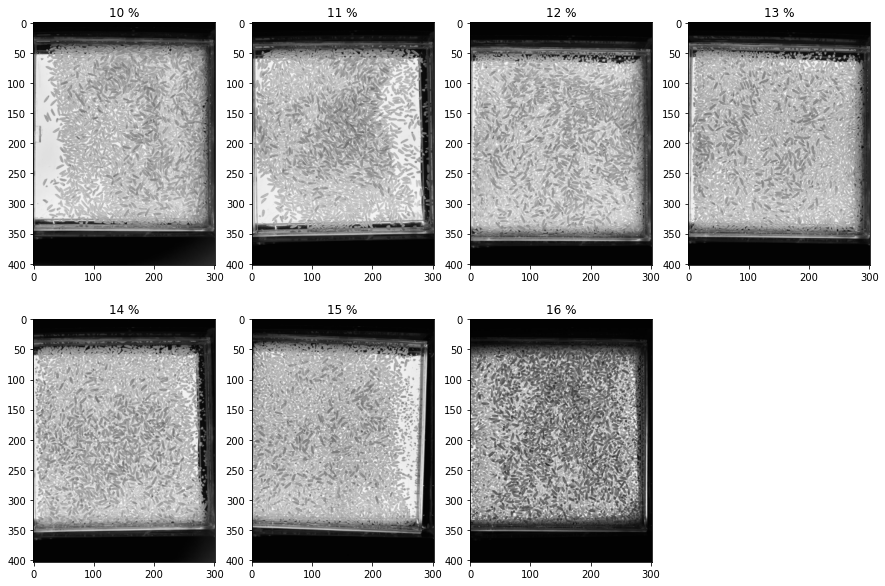

In [6]:
fig=plt.figure(figsize=(15, 10)) 
ax1 = fig.add_subplot(2,4,1)
image = read_imgHEIC(data_path[0][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10 %")
ax2 = fig.add_subplot(2,4,2)
image = read_imgHEIC(data_path[1][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11 %")
ax3 = fig.add_subplot(2,4,3)
image = read_imgHEIC(data_path[2][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12 %")
ax4 = fig.add_subplot(2,4,4)
image = read_imgHEIC(data_path[3][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13 %")
ax5 = fig.add_subplot(2,4,5)
image = read_imgHEIC(data_path[4][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14 %")
ax6 = fig.add_subplot(2,4,6)
image = read_imgHEIC(data_path[5][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15 %")
ax7 = fig.add_subplot(2,4,7)
image = read_imgHEIC(data_path[6][random.randint(0, 25)]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16 %")

In [7]:
def fd_gray(gray, bins, mask=None):
    # compute the gray color histogram
    hist  = cv2.calcHist([gray], [0], None, [bins], [0, 256])
    # normalize the histogram
    cv2.normalize(hist, hist)
    # return the histogram
    return hist, hist.flatten()

In [153]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=3
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        # Uniform LBP is used
        P=16; R=2
        lbp_ = local_binary_pattern(gray, P, R, method='uniform')
        n_bins = int(lbp_.max() + 1)
        hist_, bin_edges = np.histogram(lbp_.ravel(), bins=n_bins, range=(0, n_bins), density=True)
        arr_img_hist.append(hist_)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["P"] = P
    pdGrayFeatures["R"] = R
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [154]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(P)+'_'+str(R)+'bins.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,16,17,scale,P,R,height,width,channels,IMAGENAME,HUMIDITY
0,0.076019,0.055278,0.023981,0.014907,0.010741,0.013426,0.013333,0.031759,0.057778,0.062222,...,0.140463,0.362778,3,16,2,120,90,3,IMG_6627.HEIC,10
1,0.077130,0.057222,0.023426,0.013704,0.010463,0.011111,0.012685,0.028056,0.058426,0.059352,...,0.146296,0.368611,3,16,2,120,90,3,IMG_6628.HEIC,10
2,0.075926,0.055278,0.027870,0.013981,0.011019,0.011111,0.013426,0.031944,0.059444,0.058056,...,0.140093,0.359074,3,16,2,120,90,3,IMG_6629.HEIC,10
3,0.075556,0.056204,0.026667,0.014815,0.010741,0.011667,0.013704,0.030556,0.058981,0.058426,...,0.141574,0.361759,3,16,2,120,90,3,IMG_6630.HEIC,10
4,0.074167,0.054259,0.024722,0.016019,0.010278,0.012685,0.017407,0.032315,0.059074,0.057685,...,0.141111,0.359722,3,16,2,120,90,3,IMG_6631.HEIC,10
5,0.074907,0.052315,0.022222,0.014815,0.012593,0.015648,0.016296,0.034352,0.058796,0.065093,...,0.140556,0.352963,3,16,2,120,90,3,IMG_6632.HEIC,10
6,0.077130,0.058704,0.023889,0.015463,0.010648,0.014167,0.012870,0.026389,0.048796,0.057130,...,0.141204,0.381019,3,16,2,120,90,3,IMG_6633.HEIC,10
7,0.078241,0.052315,0.024722,0.014722,0.012963,0.011111,0.015185,0.033426,0.055741,0.060093,...,0.140370,0.360741,3,16,2,120,90,3,IMG_6634.HEIC,10
8,0.078889,0.051667,0.022315,0.012407,0.012500,0.012500,0.012315,0.029630,0.063148,0.061389,...,0.143056,0.367407,3,16,2,120,90,3,IMG_6635.HEIC,10
9,0.074537,0.053611,0.025556,0.014537,0.010648,0.012407,0.013519,0.032778,0.063981,0.062222,...,0.134537,0.359352,3,16,2,120,90,3,IMG_6636.HEIC,10


# Classification

In [155]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-8]
#X

In [156]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [157]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [158]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [159]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [160]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.736842,0.846939,0.714286,0.774977,LBP,C3,RF_C,3,16,2,120,90,3
1,2,0.736842,0.835714,0.738095,0.783877,LBP,C3,RF_C,3,16,2,120,90,3
2,3,0.631579,0.654762,0.619048,0.636404,LBP,C3,RF_C,3,16,2,120,90,3
3,4,0.684211,0.771429,0.666667,0.715232,LBP,C3,RF_C,3,16,2,120,90,3
4,5,0.526316,0.661905,0.547619,0.599363,LBP,C3,RF_C,3,16,2,120,90,3
5,6,0.789474,0.821429,0.809524,0.815433,LBP,C3,RF_C,3,16,2,120,90,3
6,7,0.473684,0.500000,0.500000,0.500000,LBP,C3,RF_C,3,16,2,120,90,3
7,8,0.684211,0.795238,0.714286,0.752591,LBP,C3,RF_C,3,16,2,120,90,3
8,9,0.473684,0.652381,0.523810,0.581068,LBP,C3,RF_C,3,16,2,120,90,3
9,10,0.526316,0.604762,0.547619,0.574774,LBP,C3,RF_C,3,16,2,120,90,3


In [161]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C3,RF_C,0.626316,0.638095,0.673372,0.714456


### MLP Classifier

In [162]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [163]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [164]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.578947,0.607143,0.571429,0.588745,LBP,C3,MLP_C,3,16,2,120,90,3
1,2,0.631579,0.630952,0.619048,0.624943,LBP,C3,MLP_C,3,16,2,120,90,3
2,3,0.631579,0.728571,0.642857,0.683036,LBP,C3,MLP_C,3,16,2,120,90,3
3,4,0.684211,0.795238,0.642857,0.710974,LBP,C3,MLP_C,3,16,2,120,90,3
4,5,0.473684,0.619048,0.452381,0.522751,LBP,C3,MLP_C,3,16,2,120,90,3
5,6,0.631579,0.690476,0.619048,0.652814,LBP,C3,MLP_C,3,16,2,120,90,3
6,7,0.736842,0.833333,0.738095,0.782828,LBP,C3,MLP_C,3,16,2,120,90,3
7,8,0.631579,0.761905,0.666667,0.711111,LBP,C3,MLP_C,3,16,2,120,90,3
8,9,0.368421,0.630952,0.380952,0.475070,LBP,C3,MLP_C,3,16,2,120,90,3
9,10,0.736842,0.785714,0.761905,0.773626,LBP,C3,MLP_C,3,16,2,120,90,3


In [165]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C3,MLP_C,0.610526,0.609524,0.65259,0.708333


### XGBoost Classifier

In [166]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [167]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; dtFoldTrain["P"]=P; dtFoldTrain["R"]=R; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'_'+str(P)+'_'+str(R)+'_bins.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,P,R,height,width,channels
0,1,0.578947,0.700000,0.547619,0.614504,LBP,C3,XGB_C,3,16,2,120,90,3
1,2,0.631579,0.619048,0.619048,0.619048,LBP,C3,XGB_C,3,16,2,120,90,3
2,3,0.684211,0.666667,0.666667,0.666667,LBP,C3,XGB_C,3,16,2,120,90,3
3,4,0.578947,0.797619,0.619048,0.697079,LBP,C3,XGB_C,3,16,2,120,90,3
4,5,0.526316,0.404762,0.547619,0.465476,LBP,C3,XGB_C,3,16,2,120,90,3
5,6,0.526316,0.592857,0.547619,0.569341,LBP,C3,XGB_C,3,16,2,120,90,3
6,7,0.526316,0.571429,0.523810,0.546584,LBP,C3,XGB_C,3,16,2,120,90,3
7,8,0.684211,0.726190,0.690476,0.707883,LBP,C3,XGB_C,3,16,2,120,90,3
8,9,0.526316,0.585034,0.547619,0.565709,LBP,C3,XGB_C,3,16,2,120,90,3
9,10,0.473684,0.464286,0.500000,0.481481,LBP,C3,XGB_C,3,16,2,120,90,3


In [168]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,LBP,C3,XGB_C,0.573684,0.580952,0.593377,0.612789


# External validation

In [169]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C3_10,5,"[DATA/TEST/C3/C3_10/IMG_6622.HEIC, DATA/TEST/C..."
1,C3_11,5,"[DATA/TEST/C3/C3_11/IMG_6717.HEIC, DATA/TEST/C..."
2,C3_12,5,"[DATA/TEST/C3/C3_12/IMG_6845.HEIC, DATA/TEST/C..."
3,C3_13,5,"[DATA/TEST/C3/C3_13/IMG_6987.HEIC, DATA/TEST/C..."
4,C3_14,5,"[DATA/TEST/C3/C3_14/IMG_7239.HEIC, DATA/TEST/C..."
5,C3_15,5,"[DATA/TEST/C3/C3_15/IMG_7376.HEIC, DATA/TEST/C..."
6,C3_16,5,"[DATA/TEST/C3/C3_16/IMG_7506.HEIC, DATA/TEST/C..."


In [170]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [171]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        # Uniform LBP is used
        P=16; R=2
        lbp_ = local_binary_pattern(gray, P, R, method='uniform')
        n_bins = int(lbp_.max() + 1)
        hist_, bin_edges = np.histogram(lbp_.ravel(), bins=n_bins, range=(0, n_bins), density=True)
        arr_img_hist.append(hist_)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["P"] = P
    pdGrayFeatures["R"] = R
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [172]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'_'+str(P)+'_'+str(R)+'bins.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,16,17,scale,P,R,height,width,channels,IMAGENAME,HUMIDITY
0,0.082037,0.062685,0.020556,0.012593,0.007593,0.010648,0.012685,0.022407,0.047963,0.052963,...,0.148611,0.384074,3,16,2,120,90,3,IMG_6622.HEIC,10
1,0.075370,0.060648,0.024907,0.012593,0.009074,0.009074,0.012963,0.026111,0.048333,0.052130,...,0.155463,0.380000,3,16,2,120,90,3,IMG_6623.HEIC,10
2,0.077593,0.060278,0.023333,0.013611,0.011481,0.010833,0.012593,0.024537,0.057037,0.054259,...,0.145926,0.370093,3,16,2,120,90,3,IMG_6624.HEIC,10
3,0.077593,0.062222,0.023056,0.012963,0.009907,0.010648,0.012315,0.028426,0.053056,0.054537,...,0.145278,0.370093,3,16,2,120,90,3,IMG_6625.HEIC,10
4,0.076852,0.052593,0.020093,0.011852,0.008981,0.013333,0.015093,0.032500,0.061759,0.058981,...,0.140093,0.371481,3,16,2,120,90,3,IMG_6626.HEIC,10
0,0.076944,0.054444,0.022593,0.010370,0.009815,0.011759,0.012593,0.028981,0.046296,0.063981,...,0.164722,0.359907,3,16,2,120,90,3,IMG_6717.HEIC,11
1,0.076389,0.055093,0.019907,0.010648,0.009630,0.012500,0.012222,0.028611,0.045370,0.060741,...,0.167130,0.366574,3,16,2,120,90,3,IMG_6721.HEIC,11
2,0.073889,0.054352,0.019815,0.010463,0.006204,0.011667,0.011852,0.030926,0.055093,0.064259,...,0.162778,0.362037,3,16,2,120,90,3,IMG_6724.HEIC,11
3,0.072870,0.058519,0.020000,0.012500,0.007778,0.012130,0.013611,0.032685,0.052037,0.060648,...,0.165833,0.353519,3,16,2,120,90,3,IMG_6728.HEIC,11
4,0.074907,0.051481,0.022593,0.012500,0.010833,0.014074,0.015833,0.028333,0.046019,0.058148,...,0.165093,0.361574,3,16,2,120,90,3,IMG_6731.HEIC,11


In [173]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [174]:
X_test = dtFeaturesTest.values[:, :-8]
#X_test

In [175]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [176]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [177]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.23      0.60      0.33         5
     Class 1       1.00      0.60      0.75         5
     Class 2       0.83      1.00      0.91         5
     Class 3       0.00      0.00      0.00         5
     Class 4       0.33      0.20      0.25         5
     Class 5       0.80      0.80      0.80         5
     Class 6       0.33      0.20      0.25         5

    accuracy                           0.49        35
   macro avg       0.50      0.49      0.47        35
weighted avg       0.50      0.49      0.47        35



## MLP

In [178]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [179]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.60      0.60      0.60         5
     Class 1       0.75      0.60      0.67         5
     Class 2       0.50      0.80      0.62         5
     Class 3       0.00      0.00      0.00         5
     Class 4       0.33      0.20      0.25         5
     Class 5       0.75      0.60      0.67         5
     Class 6       0.44      0.80      0.57         5

    accuracy                           0.51        35
   macro avg       0.48      0.51      0.48        35
weighted avg       0.48      0.51      0.48        35



## XGBC

In [180]:
y_pred = modelXGBC.predict(X_test_scale) 

In [181]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       0.33      0.60      0.43         5
     Class 1       1.00      1.00      1.00         5
     Class 2       1.00      1.00      1.00         5
     Class 3       0.00      0.00      0.00         5
     Class 4       0.20      0.20      0.20         5
     Class 5       0.80      0.80      0.80         5
     Class 6       0.67      0.80      0.73         5

    accuracy                           0.63        35
   macro avg       0.57      0.63      0.59        35
weighted avg       0.57      0.63      0.59        35

